# 02 · Statistical analysis: BankSight

**Questions this notebook answers (before any model is trained)**
1. How different are relief rates between products, and how sure are we? (confidence intervals)
2. Which products differ *significantly* from the rest, after correcting for running many tests?
3. Which product rates changed between the train and validation periods?
4. Which candidate features carry signal **beyond product**? (the question that decides what the model gets to use)
5. After adjusting for product, what are the effects of narrative length and consumer tags?


**What this does:** loads every library the notebook needs (all imports live in this one cell) and sets how tables are
printed.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4g}".format)

**What this does:** works out where the data and output folders are, creates the output folders, and sets two settings
used later. The *significance level* (ALPHA) is the p-value cut-off below which we call a result "real"; MIN_N skips groups
that are too small to test.

In [2]:
if Path.cwd().name == "notebooks":
    ROOT = Path("..")
else:
    ROOT = Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
FIG_DIR = ROOT / "reports" / "figures"
REPORT_DIR = ROOT / "reports" / "data_quality"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert WAREHOUSE.exists(), "Run notebooks 01 and 01b first (they create data/warehouse/banksight.duckdb)."

ALPHA = 0.05      # significance level, applied AFTER Benjamini-Hochberg correction
MIN_N = 50        # do not test groups smaller than this

## 1. Load train + validation (no text, no company)
Text columns are summarised inside DuckDB (length, word count, number of "XXXX" masks), so the narratives never enter pandas.

**What this does:** opens the warehouse and checks which optional columns exist in the raw table. Some samples lack
columns such as `tags`, so for a missing one we will select an empty (NULL) column instead of failing.

In [3]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
rows_found = con.sql(
    "SELECT column_name FROM information_schema.columns WHERE table_schema='raw' AND table_name='cfpb_complaints'").fetchall()
have_cols = set()
for row in rows_found:
    have_cols.add(row[0])

# build the SELECT piece for each optional column: the real column if it exists, otherwise NULL
optional_sql = {}
for name in ["issue", "state", "tags", "timely_response"]:
    if name in have_cols:
        optional_sql[name] = "r." + name + " AS " + name
    else:
        optional_sql[name] = "NULL AS " + name

**What this does:** pulls train and validation complaints with their product, outcome and three simple text measures
(characters, words, count of "XXXX" masks). Then it adds `log2_words`: the log base 2 of the word count, so one unit means
"double the length".

In [4]:
df = con.sql(f"""
    SELECT l.complaint_id, l.product_group, l.got_relief, l.split,
           {optional_sql['issue']}, {optional_sql['state']}, {optional_sql['tags']},
           {optional_sql['timely_response']},
           length(r.narrative)                                                AS narr_chars,
           len(str_split(trim(r.narrative), ' '))                             AS narr_words,
           (length(r.narrative) - length(replace(r.narrative, 'XXXX', ''))) / 4 AS n_xxxx
    FROM features.complaint_labels l
    JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible AND l.split IN ('train', 'validation')
""").df()
con.close()

df["got_relief"] = df["got_relief"].astype(int)
df["narr_words"] = df["narr_words"].fillna(1).clip(lower=1)   # avoid log of 0
df["log2_words"] = np.log2(df["narr_words"])

**What this does:** splits the data into the train and validation tables and prints how many rows each has, plus the
overall train relief rate.

In [5]:
print(df["split"].value_counts().to_string())
tr = df[df["split"] == "train"].copy()
va = df[df["split"] == "validation"].copy()
print(f"\ntrain rows {len(tr):,} | validation rows {len(va):,} | train relief rate {tr.got_relief.mean() * 100:.2f}%")

split
train         103777
validation     18537

train rows 103,777 | validation rows 18,537 | train relief rate 23.70%


## 2. Relief rate by product with 95% confidence intervals  *(paste this table back)*
Wilson intervals (reliable for small counts and for rates near 0% or 100%). Small groups get wide intervals, so
their rates should be read with care.

**What this does:** counts complaints and relief cases per product in train and computes the relief rate with a 95%
confidence interval. A *Wilson confidence interval* is a range that likely contains the true rate; it behaves well even for
small groups.

In [6]:
prod_tr = tr.groupby("product_group")["got_relief"].agg(n="size", relief="sum")
low, high = proportion_confint(prod_tr["relief"], prod_tr["n"], alpha=0.05, method="wilson")
prod_tr["rate_pct"] = prod_tr["relief"] / prod_tr["n"] * 100
prod_tr["ci_low_pct"] = low * 100
prod_tr["ci_high_pct"] = high * 100
prod_tr["ci_width_pp"] = prod_tr["ci_high_pct"] - prod_tr["ci_low_pct"]
prod_tr = prod_tr.sort_values("rate_pct", ascending=False)
display(prod_tr[["n", "relief", "rate_pct", "ci_low_pct", "ci_high_pct", "ci_width_pp"]])

,n,relief,rate_pct,ci_low_pct,ci_high_pct,ci_width_pp
product_group,,,,,,
Credit reporting,19614,9662,49.26,48.56,49.96,1.399
Credit or prepaid card,16915,5861,34.65,33.94,35.37,1.434
Debt collection,15678,4009,25.57,24.89,26.26,1.366
Bank account,16716,3080,18.43,17.85,19.02,1.175
Debt or credit management,688,81,11.77,9.575,14.4,4.822
Payday / personal loan,2772,230,8.297,7.327,9.383,2.056
Vehicle loan or lease,4393,363,8.263,7.485,9.114,1.629
Money transfer / virtual currency,15700,776,4.943,4.615,5.293,0.6784
Mortgage,6837,333,4.871,4.385,5.407,1.021


**What this does:** draws one dot per product (its relief rate) with a bar for the 95% interval, and a dashed line for the
overall rate. The figure is saved as a PNG.

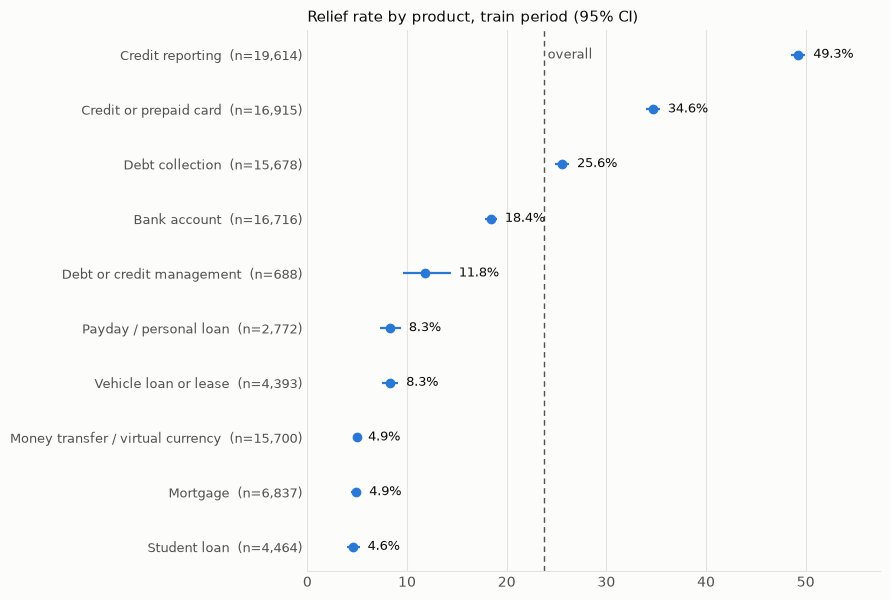

In [7]:
INK, INK2, GRID, SERIES, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#fcfcfb"
overall_rate = tr["got_relief"].mean() * 100

plot_data = prod_tr.sort_values("rate_pct")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(plot_data) + 1.6), facecolor=SURFACE)
y_positions = np.arange(len(plot_data))
left_err = plot_data["rate_pct"] - plot_data["ci_low_pct"]
right_err = plot_data["ci_high_pct"] - plot_data["rate_pct"]
ax.errorbar(plot_data["rate_pct"], y_positions, xerr=[left_err, right_err],
            fmt="o", color=SERIES, ecolor=SERIES, elinewidth=1.6, capsize=0, markersize=6)

labels = []
for product, n in zip(plot_data.index, plot_data["n"]):
    labels.append(f"{product}  (n={int(n):,})")
ax.set_yticks(y_positions)
ax.set_yticklabels(labels, color=INK, fontsize=9)

# write the rate just to the right of each interval
for i in range(len(plot_data)):
    ax.text(plot_data["ci_high_pct"].iloc[i] + 0.8, i, f"{plot_data['rate_pct'].iloc[i]:.1f}%",
            va="center", color=INK, fontsize=9)

ax.axvline(overall_rate, color=INK2, linewidth=1, linestyle=(0, (4, 3)))
ax.text(overall_rate, len(plot_data) - 1, " overall", color=INK2, fontsize=9, va="center")
ax.set_xlim(0, max(plot_data["ci_high_pct"]) * 1.15)
ax.set_title("Relief rate by product, train period (95% CI)", loc="left", color=INK, fontsize=11)
ax.set_facecolor(SURFACE)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK2, length=0)
plt.tight_layout()
fig.savefig(FIG_DIR / "02_relief_by_product_ci.png", dpi=150, facecolor=SURFACE)
plt.show()

## 3. Is the product effect real? Overall test plus one test per product
* **Overall:** chi-square test of product × relief, with Cramér's V as the effect size (0 = no link, 1 = perfect link).
* **Per product:** each product against all other complaints. Ten tests at once means some "significant" results would appear
  by luck, so the p-values are corrected with **Benjamini-Hochberg** (false discovery rate). Judge by `p_adj`, not `p`.

**What this does:** tests whether relief depends on product at all. A *chi-square test* compares the observed counts with
what we would see if product did not matter; the p-value is the chance of such a gap by luck alone. *Cramér's V* turns the
result into an effect size from 0 to 1.

In [8]:
ct = pd.crosstab(tr["product_group"], tr["got_relief"])
chi2, p_overall, dof, expected = stats.chi2_contingency(ct)
cramers_v = float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))
print(f"Overall product x relief: chi2={chi2:,.0f}, dof={dof}, p={max(p_overall, 1e-300):.3g}, Cramer's V={cramers_v:.3f}")

Overall product x relief: chi2=14,787, dof=9, p=1e-300, Cramer's V=0.377


**What this does:** compares each product with all the other complaints combined. For each one it runs a 2x2 chi-square
test and also computes the rate difference in percentage points with a 95% interval (rate difference +/- 1.96 standard
errors). A p-value is never exactly 0, so very tiny ones are floored at 1e-300.

In [9]:
rows = []
total_n = len(tr)
total_relief = int(tr["got_relief"].sum())
for product, r in prod_tr.iterrows():
    if r["n"] < MIN_N:
        continue   # too small to test
    this_relief = r["relief"]
    this_n = r["n"]
    rest_relief = total_relief - this_relief
    rest_n = total_n - this_n

    table = np.array([[this_relief, this_n - this_relief], [rest_relief, rest_n - rest_relief]])
    p_value = max(stats.chi2_contingency(table)[1], 1e-300)

    rate_this = this_relief / this_n
    rate_rest = rest_relief / rest_n
    std_err = np.sqrt(rate_this * (1 - rate_this) / this_n + rate_rest * (1 - rate_rest) / rest_n)
    diff = rate_this - rate_rest
    rows.append({"product_group": product, "n": int(this_n), "rate_pct": rate_this * 100, "rest_pct": rate_rest * 100,
                 "diff_pp": diff * 100, "diff_ci_low": (diff - 1.96 * std_err) * 100,
                 "diff_ci_high": (diff + 1.96 * std_err) * 100, "p": p_value})
vs_rest = pd.DataFrame(rows).set_index("product_group")

**What this does:** corrects the p-values for running many tests at once. *Benjamini-Hochberg* controls the share of false
alarms among the results we call significant, giving an adjusted p-value (`p_adj`). Then it flags products whose `p_adj`
is below ALPHA.

In [10]:
vs_rest["p_adj"] = multipletests(vs_rest["p"], method="fdr_bh")[1]
vs_rest["significant"] = vs_rest["p_adj"] < ALPHA
display(vs_rest.sort_values("diff_pp", ascending=False))

,n,rate_pct,rest_pct,diff_pp,diff_ci_low,diff_ci_high,p,p_adj,significant
product_group,,,,,,,,,
Credit reporting,19614,49.26,17.75,31.51,30.77,32.26,1e-300,3.333e-300,True
Credit or prepaid card,16915,34.65,21.57,13.08,12.31,13.84,6.684e-293,1.671e-292,True
Debt collection,15678,25.57,23.37,2.198,1.46,2.936,2.628e-09,2.628e-09,True
Bank account,16716,18.43,24.72,-6.293,-6.947,-5.639,1.139e-68,1.424e-68,True
Debt or credit management,688,11.77,23.78,-12.01,-14.43,-9.589,2.159e-13,2.399e-13,True
Payday / personal loan,2772,8.297,24.13,-15.83,-16.89,-14.77,4.244e-83,6.063e-83,True
Vehicle loan or lease,4393,8.263,24.39,-16.12,-16.98,-15.27,2.392e-133,3.987e-133,True
Student loan,4464,4.592,24.56,-19.97,-20.64,-19.3,1.177e-206,2.353e-206,True
Mortgage,6837,4.871,25.03,-20.16,-20.74,-19.58,1e-300,3.333e-300,True


## 4. Did product relief rates change between train and validation?  *(paste this table back)*
Same idea, comparing the same product in two periods. This quantifies the within-product drift we saw in notebook 01b,
using data that is not the test set. BH correction again.

**What this does:** computes the same counts and Wilson intervals as in section 2, but for the validation rows.

In [11]:
prod_va = va.groupby("product_group")["got_relief"].agg(n="size", relief="sum")
low, high = proportion_confint(prod_va["relief"], prod_va["n"], alpha=0.05, method="wilson")
prod_va["rate_pct"] = prod_va["relief"] / prod_va["n"] * 100
prod_va["ci_low_pct"] = low * 100
prod_va["ci_high_pct"] = high * 100
prod_va["ci_width_pp"] = prod_va["ci_high_pct"] - prod_va["ci_low_pct"]

**What this does:** for each product present in both periods (and big enough in both), tests whether the validation rate
differs from the train rate, using the same 2x2 chi-square test and interval as before. Then it applies the
Benjamini-Hochberg correction and flags products that changed.

In [12]:
rows = []
shared_products = prod_tr.index.intersection(prod_va.index)
for product in shared_products:
    val_row = prod_va.loc[product]
    train_row = prod_tr.loc[product]
    if min(val_row["n"], train_row["n"]) < MIN_N:
        continue
    table = np.array([[val_row["relief"], val_row["n"] - val_row["relief"]],
                      [train_row["relief"], train_row["n"] - train_row["relief"]]])
    p_value = max(stats.chi2_contingency(table)[1], 1e-300)

    rate_val = val_row["relief"] / val_row["n"]
    rate_train = train_row["relief"] / train_row["n"]
    std_err = np.sqrt(rate_val * (1 - rate_val) / val_row["n"] + rate_train * (1 - rate_train) / train_row["n"])
    diff = rate_val - rate_train
    rows.append({"product_group": product, "n_train": int(train_row["n"]), "n_val": int(val_row["n"]),
                 "train_pct": rate_train * 100, "val_pct": rate_val * 100, "change_pp": diff * 100,
                 "ci_low": (diff - 1.96 * std_err) * 100, "ci_high": (diff + 1.96 * std_err) * 100, "p": p_value})
drift = pd.DataFrame(rows).set_index("product_group")
drift["p_adj"] = multipletests(drift["p"], method="fdr_bh")[1]
drift["changed"] = drift["p_adj"] < ALPHA
display(drift.sort_values("change_pp"))

,n_train,n_val,train_pct,val_pct,change_pp,ci_low,ci_high,p,p_adj,changed
product_group,,,,,,,,,,
Credit reporting,19614,4016,49.26,39.72,-9.545,-11.21,-7.877,3.187e-28,3.187e-27,True
Credit or prepaid card,16915,2930,34.65,28.53,-6.117,-7.903,-4.332,1.163e-10,3.877e-10,True
Payday / personal loan,2772,653,8.297,4.9,-3.397,-5.345,-1.448,0.004288,0.01072,True
Student loan,4464,451,4.592,1.774,-2.818,-4.183,-1.454,0.007358,0.01472,True
Bank account,16716,2820,18.43,17.06,-1.369,-2.876,0.1388,0.08632,0.1439,False
Mortgage,6837,1062,4.871,3.766,-1.104,-2.358,0.1495,0.1335,0.1907,False
Vehicle loan or lease,4393,928,8.263,7.651,-0.6123,-2.506,1.282,0.5801,0.6446,False
Debt collection,15678,3754,25.57,25.65,0.08177,-1.473,1.637,0.9344,0.9344,False
Debt or credit management,688,175,11.77,15.43,3.655,-2.214,9.524,0.2392,0.299,False


**What this does:** plots each product as a dot: train rate on the x axis, validation rate on the y axis. Dots on the dashed
diagonal did not change. Dots are numbered, and the key on the right gives the product names (this avoids overlapping
labels).

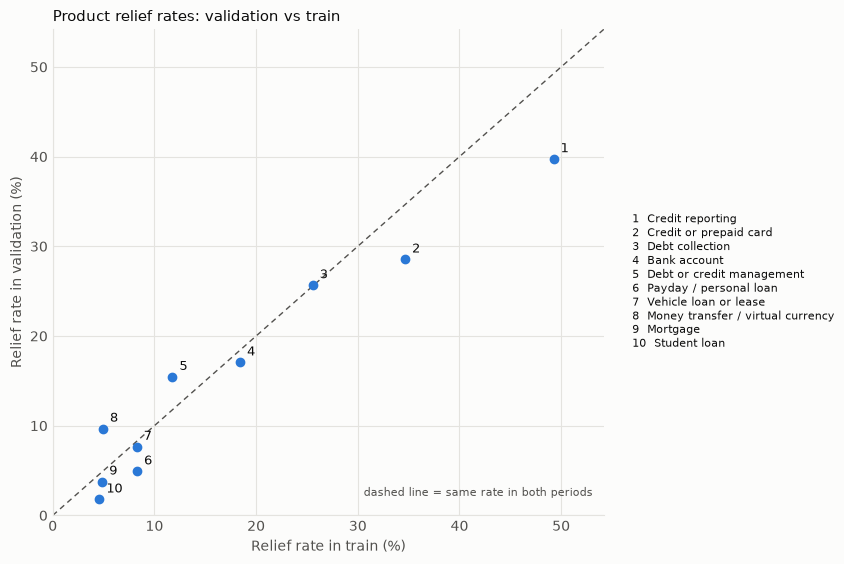

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 6.0), facecolor=SURFACE)
axis_limit = max(drift["train_pct"].max(), drift["val_pct"].max()) * 1.1
ax.plot([0, axis_limit], [0, axis_limit], color=INK2, linewidth=1, linestyle=(0, (4, 3)))
ax.scatter(drift["train_pct"], drift["val_pct"], color=SERIES, s=36, zorder=3)
ax.text(axis_limit * 0.98, axis_limit * 0.04, "dashed line = same rate in both periods", color=INK2, fontsize=8, ha="right")

key_lines = []
number = 1
for product in drift.index:
    ax.annotate(str(number), (drift.loc[product, "train_pct"], drift.loc[product, "val_pct"]),
                xytext=(5, 5), textcoords="offset points", color=INK, fontsize=9)
    key_lines.append(f"{number}  {product}")
    number = number + 1

ax.set_xlim(0, axis_limit)
ax.set_ylim(0, axis_limit)
ax.set_xlabel("Relief rate in train (%)", color=INK2)
ax.set_ylabel("Relief rate in validation (%)", color=INK2)
ax.set_title("Product relief rates: validation vs train", loc="left", color=INK, fontsize=11)
ax.set_facecolor(SURFACE)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=INK2, length=0)

fig.text(0.70, 0.5, "\n".join(key_lines), color=INK, fontsize=8, va="center")   # key to the numbered dots
fig.subplots_adjust(left=0.09, right=0.67, bottom=0.11, top=0.92)
fig.savefig(FIG_DIR / "02_train_vs_validation_by_product.png", dpi=150, facecolor=SURFACE)
plt.show()

## 5. Which features add signal beyond product?  *(paste this table back)*
Product alone explains a lot. A feature is only worth giving the model if it improves on the **product-only** logistic
model. For each candidate we fit `product + feature` on the train rows and run a **likelihood-ratio test** against
`product only`:
* `lr_chi2`, `df`, `p` — is the improvement bigger than chance?
* `delta_aic` — negative means better after penalising the extra parameters (below -10 is a clear gain).
* `mcfadden_gain` — how much extra "explained variation" the feature adds (small numbers are normal for complaint data).

Rare categories are pooled into "Other" so that no dummy variable has a handful of rows.

**What this does:** merges rare categories of `issue`, `state` and `tags` into "Other" so no category has only a handful
of rows. Missing values become their own "Missing" category. For each column we keep only categories with at least a
minimum count (and, for issue and state, only the most common ones).

In [14]:
# (column, new column, minimum rows per category, keep only this many most common categories or None)
pooling_plan = [("issue", "issue_p", 200, 30),
                ("state", "state_p", 500, 15),
                ("tags", "tags_p", 100, None)]
for column, new_column, min_count, top_k in pooling_plan:
    # an empty column arrives from DuckDB as integer type, which cannot hold text: go through object first
    values = tr[column].astype("object")
    values = values.where(values.notna(), "Missing").astype(str)
    counts = values.value_counts()
    keep = set(counts[counts >= min_count].index)
    if top_k:
        keep = keep & set(counts.head(top_k).index)
    tr[new_column] = values.where(values.isin(keep), "Other")

**What this does:** builds two simple numeric features from the "XXXX" mask count: whether any mask is present, and its
log (log1p = log(1 + x), which tames very large counts). Then it lists the candidate features to test, each paired with
its formula term.

In [15]:
tr["xxxx_any"] = (tr["n_xxxx"].fillna(0) > 0).astype(int)
tr["log1p_xxxx"] = np.log1p(tr["n_xxxx"].fillna(0))

candidates = {
    "issue (top 30)": ("C(issue_p)", "issue_p"),
    "narrative length (log2 words)": ("log2_words", None),
    "number of XXXX masks": ("log1p_xxxx", None),
    "state (top 15)": ("C(state_p)", "state_p"),
    "consumer tags": ("C(tags_p)", "tags_p"),
}

**What this does:** fits the baseline *logistic regression* (a model that predicts a yes/no outcome such as relief) using
product only, and prints its fit statistics. AIC is a fit score that penalises complexity (lower is better); McFadden R2
is a rough "share of variation explained".

In [16]:
base_model = smf.logit("got_relief ~ C(product_group)", data=tr).fit(disp=False, maxiter=200)
print(f"product-only model: n={int(base_model.nobs):,}, log-likelihood={base_model.llf:,.0f}, "
      f"AIC={base_model.aic:,.0f}, McFadden R2={base_model.prsquared:.4f}")

product-only model: n=103,777, log-likelihood=-48,955, AIC=97,930, McFadden R2=0.1386


**What this does:** adds each candidate feature to the product-only model, one at a time, and tests whether it helps. The
*likelihood-ratio test* compares the two models: twice the gain in log-likelihood follows a chi-square distribution if the
feature is useless. Failed or impossible fits are reported in a `note` column rather than hidden.

In [17]:
rows = []
for label, (term, levels_col) in candidates.items():
    if levels_col is not None and tr[levels_col].nunique() < 2:
        rows.append({"feature": label, "note": "skipped: fewer than 2 categories (column empty or constant)"})
        continue
    try:
        bigger_model = smf.logit("got_relief ~ C(product_group) + " + term, data=tr).fit(disp=False, maxiter=200)
        lr_stat = 2 * (bigger_model.llf - base_model.llf)
        extra_df = int(bigger_model.df_model - base_model.df_model)
        rows.append({"feature": label, "df": extra_df, "lr_chi2": lr_stat,
                     "p": stats.chi2.sf(lr_stat, extra_df),
                     "delta_aic": bigger_model.aic - base_model.aic,
                     "mcfadden_gain": bigger_model.prsquared - base_model.prsquared, "note": ""})
    except Exception as error:   # separation / convergence problems are reported, not hidden
        rows.append({"feature": label, "note": "fit failed: " + type(error).__name__})
signal = pd.DataFrame(rows).set_index("feature")

**What this does:** applies the Benjamini-Hochberg correction to the feature p-values, shows the table and saves it as a
CSV.

In [18]:
has_p = signal["p"].notna()
if has_p.any():
    signal.loc[has_p, "p_adj"] = multipletests(signal.loc[has_p, "p"], method="fdr_bh")[1]
display(signal)
signal.to_csv(REPORT_DIR / "02_feature_signal_beyond_product.csv")

,df,lr_chi2,p,delta_aic,mcfadden_gain,note,p_adj
feature,,,,,,,
issue (top 30),30,"1,686",0,"-1,626",0.01483,,0
narrative length (log2 words),1,0.05856,0.8088,1.941,5.152e-07,,0.8088
number of XXXX masks,1,12.12,0.0004999,-10.12,0.0001066,,0.0006249
state (top 15),15,86.94,3.674e-12,-56.94,0.0007649,,6.124e-12
consumer tags,3,96.71,7.924e-21,-90.71,0.0008508,,1.981e-20


## 6. Adjusted effects: narrative length and consumer tags, holding product fixed  *(paste this table back)*
Odds ratios (OR) with 95% intervals from one logistic regression. **OR = 1.0 means no effect.** OR 1.2 means 20% higher
odds of relief. The length OR is *per doubling* of the word count (e.g. 50 -> 100 words).
This describes association in this sample; it does not prove that longer complaints *cause* relief.
Odds ratios also depend on which variables are in the model: leaving out a relevant variable (such as issue) pulls the
others slightly toward 1.0, so treat them as "adjusted for product" and not as exact effect sizes.

**What this does:** fits one logistic regression with product, narrative length and (if available) consumer tags together.
An *odds ratio* is the factor by which the odds of relief change for a one-unit increase; here we take it from the model
coefficients with a 95% interval, and hide the product rows and the intercept.

In [19]:
terms = ["C(product_group)", "log2_words"]
if tr["tags_p"].nunique() >= 2:
    terms.append("C(tags_p, Treatment(reference='Missing'))")
adjusted_model = smf.logit("got_relief ~ " + " + ".join(terms), data=tr).fit(disp=False, maxiter=200)

conf = adjusted_model.conf_int()
odds_table = pd.DataFrame({"odds_ratio": np.exp(adjusted_model.params), "ci_low": np.exp(conf[0]),
                           "ci_high": np.exp(conf[1]), "p": adjusted_model.pvalues})
is_product_row = odds_table.index.str.contains("product_group")
is_intercept = odds_table.index == "Intercept"
odds_table = odds_table[~is_product_row & ~is_intercept]

**What this does:** turns the awkward statsmodels row names into readable ones (for example "tag: Servicemember") and shows
the table.

In [20]:
tag_prefix = "C(tags_p, Treatment(reference='Missing'))[T."
readable_names = []
for name in odds_table.index:
    readable_names.append(name.replace(tag_prefix, "tag: ").rstrip("]"))
odds_table.index = readable_names
display(odds_table)

,odds_ratio,ci_low,ci_high,p
tag: Older American,1.077,0.9983,1.163,0.05537
"tag: Older American, Servicemember",1.095,0.9521,1.258,0.2042
tag: Servicemember,0.7423,0.6964,0.7912,5.521e-20
log2_words,1.002,0.9908,1.014,0.706


## 7. Timeliness vs relief (explanation only, never a model feature)
`timely_response` is only known after the company replies, so it must **not** be used to predict relief. Here it is
used only to describe the world.

**What this does:** if `timely_response` has data, compares the relief rate of late versus on-time responses, with Wilson
intervals as in section 2.

In [21]:
has_timely = tr["timely_response"].notna().any() and tr["timely_response"].nunique() >= 2
if has_timely:
    tr["late"] = np.where(tr["timely_response"] == "No", "late (No)", "on time (Yes)")
    timely_table = tr.groupby("late")["got_relief"].agg(n="size", relief="sum")
    low, high = proportion_confint(timely_table["relief"], timely_table["n"], alpha=0.05, method="wilson")
    timely_table["rate_pct"] = timely_table["relief"] / timely_table["n"] * 100
    timely_table["ci_low_pct"] = low * 100
    timely_table["ci_high_pct"] = high * 100
    display(timely_table[["n", "rate_pct", "ci_low_pct", "ci_high_pct"]])
else:
    print("timely_response is empty or constant in this sample; skipped.")

,n,rate_pct,ci_low_pct,ci_high_pct
late,,,,
late (No),1496,6.016,4.92,7.337
on time (Yes),102281,23.96,23.7,24.23


**What this does:** repeats the comparison as a logistic regression that holds product fixed, and prints the adjusted odds
ratio for a late response (below 1.0 means late responses go with lower odds of relief).

In [22]:
if has_timely:
    timely_model = smf.logit("got_relief ~ C(product_group) + I(timely_response == 'No')", data=tr).fit(disp=False, maxiter=200)
    late_name = ""
    for name in timely_model.params.index:
        if "timely" in name and late_name == "":
            late_name = name
    low, high = np.exp(timely_model.conf_int().loc[late_name])
    print(f"Adjusted odds ratio for a late response: {np.exp(timely_model.params[late_name]):.2f} (95% CI {low:.2f} to {high:.2f})")

Adjusted odds ratio for a late response: 0.35 (95% CI 0.28 to 0.43)


## 8. Save the tables for the model card

**What this does:** writes the three main tables to CSV files and prints where the files and figures were saved.

In [23]:
prod_tr.to_csv(REPORT_DIR / "02_relief_rate_by_product_train.csv")
vs_rest.to_csv(REPORT_DIR / "02_product_vs_rest_tests.csv")
drift.to_csv(REPORT_DIR / "02_product_drift_train_vs_validation.csv")
print("saved CSVs to", REPORT_DIR.resolve())
print("saved figures to", FIG_DIR.resolve())

saved CSVs to D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\reports\data_quality
saved figures to D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\reports\figures
